In [1]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle, Arc
from math import gcd
from functools import reduce

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(20)


def draw_chain(P, pos, ax, labels=None, r=0.09):
    """Draw a transition graph: nodes at pos, an arrow i -> j labeled p_ij whenever p_ij > 0."""
    m = len(P)
    labels = labels or [str(i + 1) for i in range(m)]
    ax.set_aspect("equal"); ax.axis("off")
    for i in range(m):
        ax.add_patch(Circle(pos[i], r, fc="#e8f1fb", ec="C0", lw=1.5, zorder=3))
        ax.text(*pos[i], labels[i], ha="center", va="center", fontsize=13, zorder=4)
    for i in range(m):
        for j in range(m):
            if P[i][j] <= 0:
                continue
            x0, y0 = pos[i]; x1, y1 = pos[j]
            if i == j:
                ax.add_patch(Arc((x0, y0 + r + 0.045), 0.1, 0.12, theta1=-30, theta2=210, ec="k", lw=1.2, zorder=2))
                ax.add_patch(FancyArrowPatch((x0 - 0.052, y0 + r + 0.075), (x0 - 0.045, y0 + r + 0.02),
                                             arrowstyle="-|>", mutation_scale=9, color="k", zorder=2))
                ax.text(x0, y0 + r + 0.135, f"{P[i][j]:g}", ha="center", fontsize=10)
            else:
                d = np.array([x1 - x0, y1 - y0]); d = d / np.hypot(*d)
                a = np.array([x0, y0]) + d * r; b = np.array([x1, y1]) - d * r
                rad = 0.25 if P[j][i] > 0 else 0.0
                ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, color="k",
                                             connectionstyle=f"arc3,rad={rad}", lw=1.2, zorder=2))
                mid = (a + b) / 2
                dx, dy = b - a
                # midpoint of matplotlib's arc3 curve = mid + 0.5 * rad * (dy, -dx); nudge a bit further out
                if rad == 0:
                    lab = mid + np.array([0.0, 0.045])
                else:
                    lab = mid + 0.5 * rad * np.array([dy, -dx]) * 1.5
                ax.text(*lab, f"{P[i][j]:g}", ha="center", va="center", fontsize=10,
                        bbox=dict(fc="white", ec="none", pad=0.5))
    xs = [p[0] for p in pos]; ys = [p[1] for p in pos]
    ax.set_xlim(min(xs) - 0.2, max(xs) + 0.2); ax.set_ylim(min(ys) - 0.25, max(ys) + 0.35)

# Discrete-Time Markov Chains

## Motivation

::: {.callout-note}
## Recall

- **Bernoulli process:** trials are independent, so the future is independent of the past.
- **Poisson process:** the fresh-start property (and memorylessness of the exponential) says the future is independent of the past.
:::

. . .

::: {.callout-warning}
## But many systems have memory

- Whether a machine works tomorrow depends on whether it works today.
- Tomorrow's weather depends on today's weather.
- A gambler's fortune after the next bet depends on the current fortune.
:::

. . .

::: {.callout-tip}
## Key idea

In a **Markov model**, the past affects the future only **through the current state**. Given the present, the future is independent of the past.
:::

# Markov Models

## Specification

::: {.callout-note}
## A discrete-time Markov model is specified by

1. A **state space** $\mathcal S=\{1,2,\ldots,m\}$ (finite). Let $X_n$ be the state at time $n=0,1,2,\ldots$
2. **Transition probabilities**
$$p_{ij}=P(X_{n+1}=j\mid X_n=i),\qquad i,j\in\mathcal S.$$
:::

. . .

::: {.callout-warning}
## Reading the definition

$p_{ij}\ge0$ and each row sums to one: $\sum_{j=1}^m p_{ij}=1$ for every $i$. Also, $p_{ij}$ does not depend on $n$ (**time homogeneity**), just as in the Bernoulli and Poisson processes.
:::

## Markov chain

::: {.callout-note}
## Definition (Markov property)

A sequence $X_0,X_1,X_2,\ldots$ is a **Markov chain** if for all times $n$ and all states $i,j,i_0,\ldots,i_{n-1}$,
$$P(X_{n+1}=j\mid X_n=i,\,X_{n-1}=i_{n-1},\ldots,X_0=i_0)=P(X_{n+1}=j\mid X_n=i)=p_{ij}.$$
:::

. . .

::: {.callout-tip}
## In words

Conditioned on the present $X_n$, the future $X_{n+1},X_{n+2},\ldots$ is independent of the past $X_0,\ldots,X_{n-1}$.
:::

## Transition probability matrix and graph

::: {.callout-note}
## Transition probability matrix

$$P=\begin{bmatrix}p_{11}&p_{12}&\cdots&p_{1m}\\p_{21}&p_{22}&\cdots&p_{2m}\\\vdots&&\ddots&\vdots\\p_{m1}&p_{m2}&\cdots&p_{mm}\end{bmatrix}$$
Row $i$ is the PMF of the next state given that we are currently in state $i$.
:::

. . .

::: {.callout-tip}
## Transition graph

Draw one node per state and an arrow $i\to j$ labeled $p_{ij}$ whenever $p_{ij}>0$. The outgoing labels from each node sum to 1.
:::

### Example: machine failure, repair, replacement

::: {.callout-warning}
## Example

Each day a machine is in one of four states:

1. **old machine, working**
2. **old machine, broken**
3. **new machine, working**
4. **new machine, in scheduled maintenance**

An old working machine breaks with probability $0.2$. A broken old machine is repaired the next day with probability $0.5$, remains broken with probability $0.2$, and is replaced with probability $0.3$. A new machine follows a strict schedule, alternating between working and maintenance days.
:::

. . .

::: {.callout-note}
## Transition matrix

$$P=\begin{bmatrix}0.8&0.2&0&0\\0.5&0.2&0.3&0\\0&0&0&1\\0&0&1&0\end{bmatrix}$$
:::

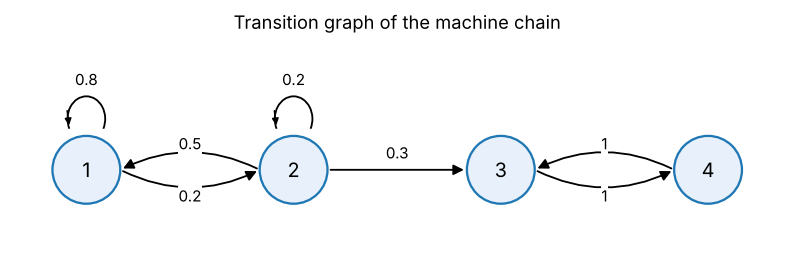

In [2]:
#| fig-height: 3.2
P = np.array([[0.8, 0.2, 0.0, 0.0],
              [0.5, 0.2, 0.3, 0.0],
              [0.0, 0.0, 0.0, 1.0],
              [0.0, 0.0, 1.0, 0.0]])
assert np.allclose(P.sum(axis=1), 1)

pos = [(0.0, 0.0), (0.55, 0.0), (1.1, 0.0), (1.65, 0.0)]
fig, ax = plt.subplots(figsize=(9, 2.6))
draw_chain(P.tolist(), pos, ax)
ax.set_title("Transition graph of the machine chain")
plt.tight_layout(); plt.show()

## Path probability

::: {.callout-note}
## Path probability

By the multiplication rule and the Markov property, the probability of a particular sequence of states, given the starting state, is the product of the transition probabilities along the path:
$$P(X_1=i_1,\ldots,X_n=i_n\mid X_0=i_0)=p_{i_0i_1}\,p_{i_1i_2}\cdots p_{i_{n-1}i_n}.$$
If $X_0$ is random, also multiply by $P(X_0=i_0)$.
:::

. . .

::: {.callout-warning}
## Example (machine chain)

Starting with a working old machine, what is the probability that the machine is broken the next two days and then replaced?
$$P(X_1=2,X_2=2,X_3=3\mid X_0=1)=p_{12}\,p_{22}\,p_{23}=0.2\cdot0.2\cdot0.3=0.012.$$
:::

In [3]:
def simulate(P, start, steps, size, rng):
    """Simulate `size` independent paths of the chain for `steps` steps."""
    m = len(P)
    cum = np.cumsum(P, axis=1)
    X = np.empty((size, steps + 1), dtype=int)
    X[:, 0] = start
    for t in range(steps):
        u = rng.random(size)
        X[:, t + 1] = (u[:, None] > cum[X[:, t]]).sum(axis=1)
    return X

X = simulate(P, start=0, steps=3, size=1_000_000, rng=rng)       # states are 0-indexed in code
hit = (X[:, 1] == 1) & (X[:, 2] == 1) & (X[:, 3] == 2)
print("simulated:", hit.mean(), "   theory:", 0.2 * 0.2 * 0.3)

simulated: 0.012107    theory: 0.012000000000000002


## $n$-step transition probabilities

::: {.callout-note}
## Definition

$$r_{ij}(n)=P(X_n=j\mid X_0=i)$$
is the probability of being in state $j$ after $n$ steps, starting from state $i$. By convention $r_{ij}(0)=1$ if $i=j$ and $0$ otherwise, and $r_{ij}(1)=p_{ij}$.
:::

. . .

::: {.callout-tip}
## Chapman–Kolmogorov equation

Condition on the state at time $n-1$ (total probability theorem plus the Markov property):
$$r_{ij}(n)=\sum_{k=1}^m r_{ik}(n-1)\,p_{kj}.$$
In matrix form, the $n$-step transition matrix is the $n$th matrix power: $R(n)=P^n$.
:::

. . .

::: {.callout-warning}
## Example (machine chain)

Starting from a working old machine, the only way to have a new machine working after two days is $1\to2\to3$, so
$$r_{13}(2)=p_{12}\,p_{23}=0.2\cdot0.3=0.06.$$
Also $r_{11}(2)=p_{11}p_{11}+p_{12}p_{21}=0.64+0.10=0.74$.
:::

In [4]:
P2 = np.linalg.matrix_power(P, 2)
print("P^2 =\n", P2)
print("r_13(2) =", P2[0, 2], "   r_11(2) =", P2[0, 0])

X = simulate(P, start=0, steps=2, size=500_000, rng=rng)
print("simulated r_13(2):", (X[:, 2] == 2).mean(), "   simulated r_11(2):", (X[:, 2] == 0).mean())

P^2 =
 [[0.74 0.2  0.06 0.  ]
 [0.5  0.14 0.06 0.3 ]
 [0.   0.   1.   0.  ]
 [0.   0.   0.   1.  ]]
r_13(2) = 0.06    r_11(2) = 0.7400000000000001
simulated r_13(2): 0.060158    simulated r_11(2): 0.740916


# Classification of States

## Accessible states

::: {.callout-note}
## Definitions

State $j$ is **accessible** from state $i$ if $r_{ij}(n)>0$ for some $n\ge0$. That is, there is a path in the transition graph from $i$ to $j$.

Let $A(i)$ denote the set of states accessible from $i$. States $i$ and $j$ **communicate** if each is accessible from the other.
:::

## Recurrent and transient states

::: {.callout-note}
## Definition

State $i$ is **recurrent** if for every $j\in A(i)$ we also have $i\in A(j)$: from anywhere we can get to from $i$, we can get back to $i$.

State $i$ is **transient** if it is not recurrent, i.e. there is some $j\in A(i)$ from which $i$ cannot be reached again.
:::

. . .

::: {.callout-warning}
## What this means in the long run

- A **transient** state is visited only finitely many times: once the chain reaches a state from which $i$ is inaccessible, it can never return.
- A **recurrent** state is visited infinitely many times.
:::

. . .

::: {.callout-tip}
## Fact

Every finite Markov chain has at least one recurrent state.
:::

## Recurrent classes

::: {.callout-note}
## Definition

If $i$ is recurrent, the states in $A(i)$ all communicate with $i$ and with each other. The set $A(i)$ is called a **recurrent class**: a collection of recurrent states that communicate with each other and with no other state.
:::

. . .

::: {.callout-tip}
## Facts

- Every recurrent state belongs to exactly one recurrent class.
- Once the chain enters a recurrent class, it **never leaves** it.
- Two states in the same recurrent class have the same set $A(\cdot)$.
:::

## Markov chain decomposition

::: {.callout-tip}
## Decomposition

The state space of any (finite) Markov chain can be decomposed into

- one or more **recurrent classes**, and
- possibly some **transient states**.
:::

. . .

::: {.callout-warning}
## Long-run behavior

- Started in a recurrent class, the chain stays in that class forever.
- Started in a transient state, the chain eventually (with probability 1) leaves the transient states and enters some recurrent class, where it stays.
:::

## Periodicity

::: {.callout-note}
## Definition

A recurrent class is **periodic** if its states can be grouped into $d>1$ disjoint subsets $S_1,\ldots,S_d$ such that every transition from a state in $S_k$ leads to a state in $S_{k+1}$ (with $S_{d+1}=S_1$). Otherwise it is **aperiodic**.
:::

. . .

::: {.callout-warning}
## Consequences

- In a periodic class, the chain moves through $S_1\to S_2\to\cdots\to S_d\to S_1\to\cdots$ in a deterministic cyclic order. For states $i$ in the class, $r_{ii}(n)=0$ unless $n$ is a multiple of $d$.
- The period $d$ is the greatest common divisor of the lengths of the cycles in the transition graph.
:::

. . .

::: {.callout-tip}
## Quick check

If a recurrent class contains a state with a self-transition ($p_{ii}>0$), the class is **aperiodic**.
:::

### Example: machine failure, repair, replacement (continued)

::: {.callout-warning}
## Classify the states of the machine chain

From the transition graph:

- $A(1)=A(2)=\{1,2,3,4\}$ and $A(3)=A(4)=\{3,4\}$.
- State 1 is **transient**: $3\in A(1)$ but $1\notin A(3)$. The same holds for state 2. Once the old machine is replaced, we never return to the old machine.
- States 3 and 4 are **recurrent**, and they communicate: $\{3,4\}$ is the only **recurrent class**.
:::

. . .

::: {.callout-note}
## Decomposition and periodicity

- Transient states: $\{1,2\}$. Recurrent class: $\{3,4\}$.
- The recurrent class is **periodic with period $d=2$**, with $S_1=\{3\}$ and $S_2=\{4\}$: every transition from state 3 goes to 4, and every transition from state 4 goes to 3.
:::

In [5]:
# Verify the classification by computation
m = len(P)
reach = np.linalg.matrix_power(np.eye(m) + (P > 0), m) > 0          # reach[i, j]: j accessible from i
A = [set(int(s) for s in np.flatnonzero(reach[i]) + 1) for i in range(m)]
recurrent = [all(i in np.flatnonzero(reach[j]) for j in np.flatnonzero(reach[i])) for i in range(m)]
print("A(i):", {i + 1: sorted(A[i]) for i in range(m)})
print("recurrent states:", [i + 1 for i in range(m) if recurrent[i]])
print("transient states:", [i + 1 for i in range(m) if not recurrent[i]])

# period of state 3: gcd of the times n at which r_33(n) > 0
Pn, times = np.eye(m), []
for n in range(1, 40):
    Pn = Pn @ P
    if Pn[2, 2] > 1e-12:
        times.append(n)
print("period of the recurrent class:", reduce(gcd, times), "  (return times start at", times[:4], ")")

A(i): {1: [1, 2, 3, 4], 2: [1, 2, 3, 4], 3: [3, 4], 4: [3, 4]}
recurrent states: [3, 4]
transient states: [1, 2]
period of the recurrent class: 2   (return times start at [2, 4, 6, 8] )


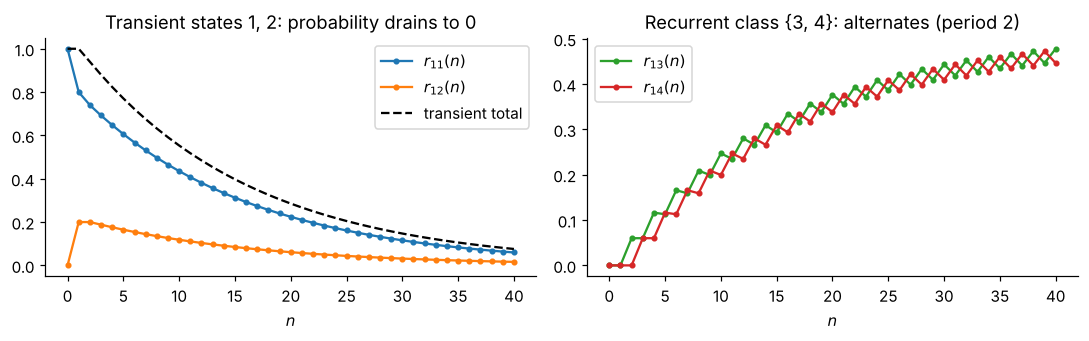

In [6]:
#| fig-height: 3.4
N = 40
R = np.array([np.linalg.matrix_power(P, n)[0] for n in range(N + 1)])     # r_{1j}(n)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for j, c in zip(range(2), ["C0", "C1"]):
    axs[0].plot(R[:, j], "o-", ms=3, color=c, label=f"$r_{{1{j+1}}}(n)$")
axs[0].plot(R[:, :2].sum(axis=1), "k--", label="transient total")
axs[0].set_title("Transient states 1, 2: probability drains to 0"); axs[0].legend()
for j, c in zip(range(2, 4), ["C2", "C3"]):
    axs[1].plot(R[:, j], "o-", ms=3, color=c, label=f"$r_{{1{j+1}}}(n)$")
axs[1].set_title("Recurrent class {3, 4}: alternates (period 2)"); axs[1].legend()
for a in axs: a.set_xlabel("$n$")
plt.tight_layout(); plt.show()